# Titanic

The files in `titanic` are the Kaggle Titanic set. `train.csv` has 891 passengers and a `Survived` label: 0 died, 1 survived. `test.csv` has 418 passengers and no label. `gender_submission.csv` is the example submission for those test passengers, not their true outcomes.

A logistic regression on the training passengers is the baseline.

Sex, port, and class are then expanded into their own columns. A decision tree, a random forest, and gradient boosting are fit on the same passengers.

The male column is then left out, because it repeats the female column.

One further tree tries the fare per person, ages filled from the title, and a depth chosen on the training passengers. That attempt scores below the tree that keeps the ticket total.


## Load the dataset


In [1]:
import pandas as pd

train = pd.read_csv("titanic/train.csv")
test = pd.read_csv("titanic/test.csv")
gender_submission = pd.read_csv("titanic/gender_submission.csv")

print("train", train.shape)
print("test", test.shape)
print("gender_submission", gender_submission.shape)
print(train.columns.tolist())
print(test.columns.tolist())

df = train.copy()


train (891, 12)
test (418, 11)
gender_submission (418, 2)
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


## Inspect the data

`df` is `train.csv`. `PassengerId`, `Name`, and `Ticket` identify the person. `Cabin` is missing for 687 of the 891 passengers. Age is missing for 177, and the port of embarkation for 2.

The model leaves out the identifier columns and `Cabin`. It keeps class, sex, age, the family counts, fare, and port.


In [2]:
print(df.head())
print(df.shape)
df.info()
print(df.describe())
print(df.isnull().sum())


   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
(8

## Investigate the target

549 passengers died and 342 survived, so death is the common outcome.

Sex and class already separate the two. Women survive at 0.742 and men at 0.189. First class survives at 0.630, second class at 0.473, and third class at 0.242.


In [3]:
print(df["Survived"].value_counts().sort_index())
print()
print(df.groupby("Sex")["Survived"].agg(["count", "mean"]))
print()
print(df.groupby("Pclass")["Survived"].agg(["count", "mean"]))


Survived
0    549
1    342
Name: count, dtype: int64

        count      mean
Sex                    
female    314  0.742038
male      577  0.188908

        count      mean
Pclass                 
1         216  0.629630
2         184  0.472826
3         491  0.242363


## Visualise relationships

The pairplot crosses age, fare, siblings and spouses aboard (`SibSp`), and parents and children aboard (`Parch`). Points are colored by whether the passenger survived. Passengers with no recorded age drop out of the age panels.


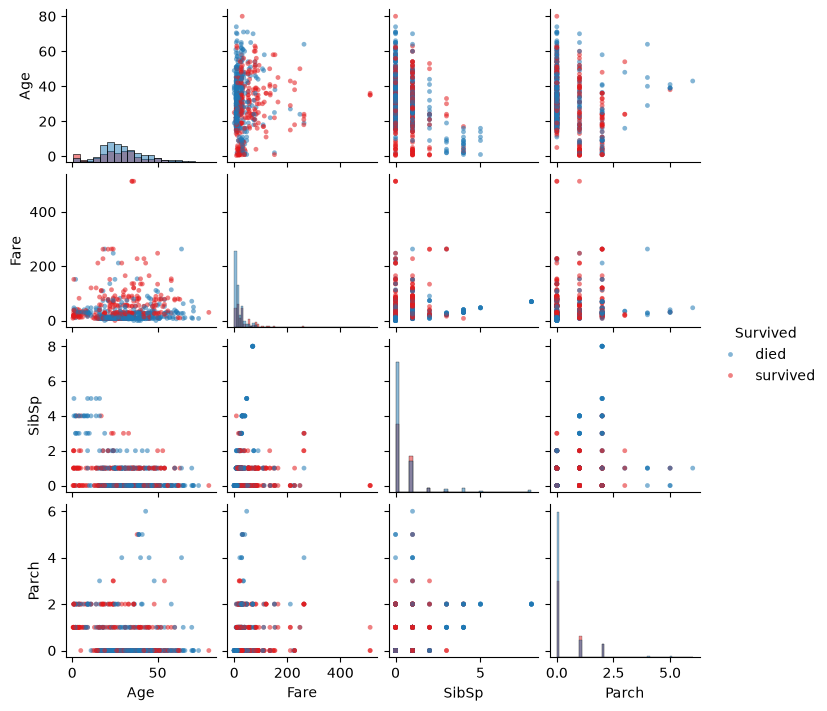

In [4]:
%matplotlib inline

import matplotlib.pyplot as plt
import seaborn as sns

plot_df = df[["Age", "Fare", "SibSp", "Parch"]].copy()
plot_df["Survived"] = df["Survived"].map({0: "died", 1: "survived"})

sns.pairplot(
    plot_df,
    hue="Survived",
    hue_order=["died", "survived"],
    palette={"died": "#1F78B4", "survived": "#E31A1C"},
    diag_kind="hist",
    height=1.8,
    plot_kws={"s": 12, "alpha": 0.55, "linewidth": 0},
)
plt.show()


## Train and test split

`test.csv` has no `Survived` column, so it cannot score the model. Hold out 20% of `train.csv` instead. Stratify on `Survived` so both sets keep the same share of survivors.


In [5]:
from sklearn.model_selection import train_test_split

model_columns = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
features = df[model_columns]
labels = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.2, random_state=42, stratify=labels
)
print("Train:", X_train.shape[0], "Test:", X_test.shape[0])
print(y_train.value_counts().sort_index())
print(y_test.value_counts().sort_index())


Train: 712 Test: 179
Survived
0    439
1    273
Name: count, dtype: int64
Survived
0    110
1     69
Name: count, dtype: int64


## Logistic regression

Age, family counts, and fare are numeric. A median imputer fills the missing ages from the training passengers only, then a `StandardScaler` puts those columns on one scale. Fare runs into the hundreds, while family counts are small, and logistic regression is sensitive to that scale.

`Pclass`, `Sex`, and `Embarked` are one-hot encoded. The two missing ports are filled with the most common training port.


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = ["Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Pclass", "Sex", "Embarked"]

numeric = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
categorical = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)
preprocess = ColumnTransformer(
    [
        ("numeric", numeric, numeric_features),
        ("categorical", categorical, categorical_features),
    ]
)

model = Pipeline(
    [
        ("preprocess", preprocess),
        ("classifier", LogisticRegression(max_iter=10000)),
    ]
)
model.fit(X_train, y_train)
print("Fitted logistic regression")


Fitted logistic regression


## Evaluate on the held-out set

The model is scored on the 179 held-out passengers from `train.csv`. Accuracy is compared with always predicting the most common training outcome. The confusion matrix shows which outcome the model actually chooses.


Accuracy: 0.804
Always predict 0: 0.615

              precision    recall  f1-score   support

        died       0.81      0.89      0.85       110
    survived       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



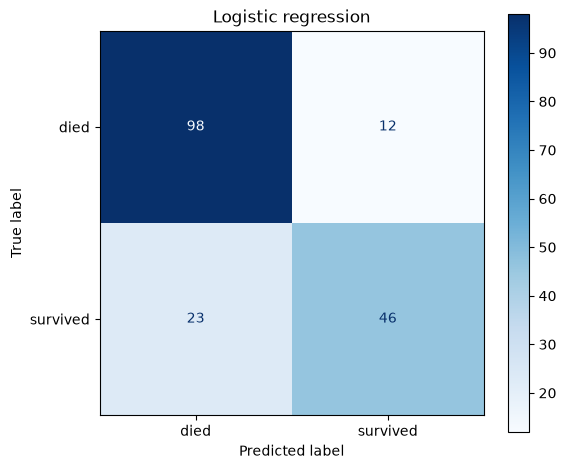

In [7]:
import numpy as np

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
)

y_pred = model.predict(X_test)
held_out = y_test.to_numpy()
predicted = np.asarray(y_pred)
common_outcome = int(y_train.mode().iloc[0])
majority = np.full(len(held_out), common_outcome)
outcome_names = ["died", "survived"]

print(f"Accuracy: {accuracy_score(held_out, predicted):.3f}")
print(f"Always predict {common_outcome}: {accuracy_score(held_out, majority):.3f}")
print()
print(classification_report(
    held_out,
    predicted,
    target_names=outcome_names,
    zero_division=0,
))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    held_out,
    predicted,
    display_labels=outcome_names,
    ax=ax,
    cmap="Blues",
)
ax.set_title("Logistic regression")
fig.tight_layout()
plt.show()


## What the baseline catches

On the 179 held-out passengers, accuracy is 0.804. Always predicting death scores 0.615.

Deaths are the easier outcome: precision 0.81 and recall 0.89. Survivors have precision 0.79 and recall 0.67, so 23 of the 69 survivors are called dead. The baseline separates the two outcomes, and a third of the survivors are still missed.


## Sex, port, and class as columns

`Name`, `Ticket`, and `Cabin` stay out. `Sex` becomes two columns, one for female and one for male. `Embarked` becomes one column per port: Cherbourg, Queenstown, and Southampton. `Pclass` becomes one column per class. The two missing ports are filled with Southampton, the common training port, before those columns are built.


## Which columns track survival

The correlations below use the training passengers only. The 179 held-out passengers stay unused.

Female sex moves with survival, and male sex moves against it by the same amount: the two columns are one fact. First class and fare move with survival. Third class and Southampton move against it. Queenstown sits near the average survival rate, so its own column is close to zero. Second class is the middle, so its column is weaker than first and third. Those columns stay, because they are the encoding of port and class.

Age and `SibSp` are close to zero as a straight line. The rates are not flat. Children survive more often than older passengers. Passengers with one sibling or spouse aboard survive more often than passengers traveling alone, and groups of three or more survive at 0.20 or below. A correlation misses that bend, so age, `SibSp`, and `Parch` stay.


In [8]:
encoded = X_train.copy()
encoded["Embarked"] = encoded["Embarked"].fillna(encoded["Embarked"].mode().iloc[0])
encoded = pd.get_dummies(encoded, columns=["Sex", "Embarked", "Pclass"])
encoded["Survived"] = y_train.to_numpy()

correlations = encoded.corr(numeric_only=True)["Survived"].drop("Survived")
correlations = correlations.reindex(correlations.abs().sort_values(ascending=False).index)
print(correlations.round(3))

print()
print("Age bands")
age_bands = pd.cut(X_train["Age"], [0, 12, 18, 40, 60, 80], right=False)
print(y_train.groupby(age_bands, observed=True).agg(["count", "mean"]).round(3))
print()
print("Siblings and spouses")
print(y_train.groupby(X_train["SibSp"]).agg(["count", "mean"]).round(3))


Sex_female    0.549
Sex_male     -0.549
Pclass_3     -0.319
Pclass_1      0.307
Fare          0.275
Embarked_C    0.180
Embarked_S   -0.179
Age          -0.084
Parch         0.084
Pclass_2      0.067
Embarked_Q    0.032
SibSp        -0.026
Name: Survived, dtype: float64

Age bands
          count   mean
Age                   
[0, 12)      54  0.593
[12, 18)     31  0.484
[18, 40)    357  0.375
[40, 60)    115  0.426
[60, 80)     17  0.118

Siblings and spouses
       count   mean
SibSp              
0        494  0.344
1        164  0.537
2         21  0.524
3         10  0.100
4         15  0.200
5          3  0.000
8          5  0.000


## Decision tree, random forest, and gradient boosting

A decision tree splits one column at a time, so it can separate a child in third class from a woman in first class. One tree fitted on 712 passengers follows the training rows closely.

A random forest averages many such trees. The average is steadier than any one tree.

Gradient boosting builds the trees in sequence. Each new tree fits the passengers the earlier trees still get wrong. That fits this table: after sex and class, the remaining mistakes are small groups, such as children and large families.

None of the three is scaled. A tree cuts one column at a time, so the size of fare does not dominate the cut the way it does in logistic regression. Missing ages are filled with the training median.


In [9]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

def make_tree_preprocess():
    numeric = Pipeline([("imputer", SimpleImputer(strategy="median"))])
    categorical = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]
    )
    return ColumnTransformer(
        [
            ("numeric", numeric, numeric_features),
            ("categorical", categorical, categorical_features),
        ]
    )


tree_models = {
    "Decision tree": Pipeline(
        [
            ("preprocess", make_tree_preprocess()),
            ("classifier", DecisionTreeClassifier(random_state=42)),
        ]
    ),
    "Random forest": Pipeline(
        [
            ("preprocess", make_tree_preprocess()),
            (
                "classifier",
                RandomForestClassifier(n_estimators=100, random_state=42),
            ),
        ]
    ),
    "Gradient boosting": Pipeline(
        [
            ("preprocess", make_tree_preprocess()),
            ("classifier", HistGradientBoostingClassifier(random_state=42)),
        ]
    ),
}

for name, candidate in tree_models.items():
    candidate.fit(X_train, y_train)
    print(f"Fitted {name}")


Fitted Decision tree


Fitted Random forest


Fitted Gradient boosting


## Compare on the held-out set

Each model is scored on the same 179 passengers. Survived recall is the share of survivors the model calls survived. The confusion matrix is for the highest accuracy.


model                    accuracy  survived recall
--------------------------------------------------
Always died                 0.615            0.000
Logistic regression         0.804            0.667
Decision tree               0.816            0.725
Random forest               0.804            0.681
Gradient boosting           0.804            0.725

Decision tree
              precision    recall  f1-score   support

        died       0.83      0.87      0.85       110
    survived       0.78      0.72      0.75        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.82      0.81       179



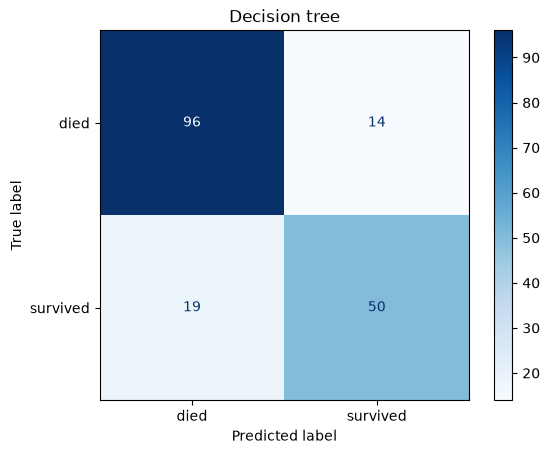

In [10]:
def survived_recall(truth, pred):
    truth = np.asarray(truth)
    pred = np.asarray(pred)
    survivors = truth == 1
    return float(np.mean(pred[survivors] == 1))


compared = {
    "Logistic regression": model,
    **tree_models,
}
rows = []
for name, candidate in compared.items():
    pred = candidate.predict(X_test)
    rows.append(
        {
            "name": name,
            "pred": np.asarray(pred),
            "accuracy": accuracy_score(y_test, pred),
            "survived recall": survived_recall(y_test, pred),
        }
    )

header = f"{'model':<22} {'accuracy':>10} {'survived recall':>16}"
print(header)
print("-" * len(header))
print(
    f"{'Always died':<22} {accuracy_score(y_test, majority):>10.3f} "
    f"{survived_recall(y_test, majority):>16.3f}"
)
for row in rows:
    print(
        f"{row['name']:<22} {row['accuracy']:>10.3f} {row['survived recall']:>16.3f}"
    )

best = max(rows, key=lambda row: (row["accuracy"], row["survived recall"]))
print()
print(best["name"])
print(classification_report(
    y_test,
    best["pred"],
    target_names=outcome_names,
    zero_division=0,
))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best["pred"],
    display_labels=outcome_names,
    cmap="Blues",
)
plt.title(best["name"])
plt.show()


## Who performs better

The decision tree reaches accuracy 0.816 and survived recall 0.725 on the 179 held-out passengers. Logistic regression was 0.804 and 0.667. That is 50 of 69 survivors called survived, against 46 for the logistic regression.

The random forest and gradient boosting stay at accuracy 0.804. Boosting's survived recall is 0.725, the same as the tree. The forest's is 0.681.


## Without the male column

`Sex_female` and `Sex_male` add up to 1 on every passenger, so the male column repeats the female one. The fits below keep `Sex_female` and leave `Sex_male` out. Port and class stay as they are: one column per port, one column per class.


['numeric__Age', 'numeric__SibSp', 'numeric__Parch', 'numeric__Fare', 'sex__Sex_female', 'categorical__Pclass_1', 'categorical__Pclass_2', 'categorical__Pclass_3', 'categorical__Embarked_C', 'categorical__Embarked_Q', 'categorical__Embarked_S']


model                    accuracy  survived recall
--------------------------------------------------
Logistic regression         0.804            0.667
Decision tree               0.827            0.725
Random forest               0.810            0.696
Gradient boosting           0.804            0.725

Decision tree
              precision    recall  f1-score   support

        died       0.84      0.89      0.86       110
    survived       0.81      0.72      0.76        69

    accuracy                           0.83       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.83      0.83      0.82       179



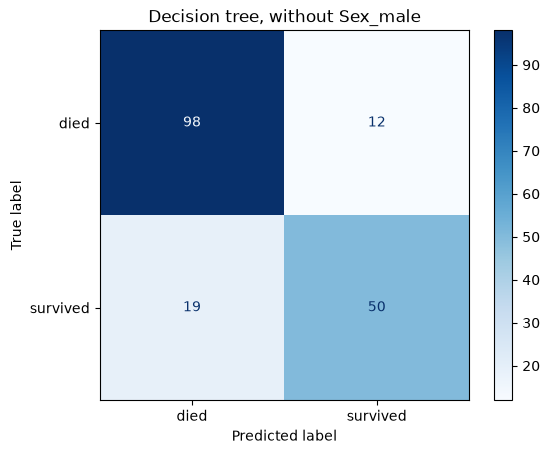

In [11]:
def make_preprocess(scale):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scaler", StandardScaler()))
    ports_and_class = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]
    )
    sex = OneHotEncoder(
        categories=[["female", "male"]],
        drop=["male"],
        sparse_output=False,
    )
    return ColumnTransformer(
        [
            ("numeric", Pipeline(numeric_steps), numeric_features),
            ("sex", sex, ["Sex"]),
            ("categorical", ports_and_class, ["Pclass", "Embarked"]),
        ]
    )


female_only = make_preprocess(False)
female_only.fit(X_train)
print(list(female_only.get_feature_names_out()))

reduced_models = {
    "Logistic regression": Pipeline(
        [
            ("preprocess", make_preprocess(True)),
            ("classifier", LogisticRegression(max_iter=10000)),
        ]
    ),
    "Decision tree": Pipeline(
        [
            ("preprocess", make_preprocess(False)),
            ("classifier", DecisionTreeClassifier(random_state=42)),
        ]
    ),
    "Random forest": Pipeline(
        [
            ("preprocess", make_preprocess(False)),
            (
                "classifier",
                RandomForestClassifier(n_estimators=100, random_state=42),
            ),
        ]
    ),
    "Gradient boosting": Pipeline(
        [
            ("preprocess", make_preprocess(False)),
            ("classifier", HistGradientBoostingClassifier(random_state=42)),
        ]
    ),
}

for name, candidate in reduced_models.items():
    candidate.fit(X_train, y_train)

header = f"{'model':<22} {'accuracy':>10} {'survived recall':>16}"
print(header)
print("-" * len(header))
reduced_rows = []
for name, candidate in reduced_models.items():
    pred = np.asarray(candidate.predict(X_test))
    reduced_rows.append(
        {
            "name": name,
            "pred": pred,
            "accuracy": accuracy_score(y_test, pred),
            "survived recall": survived_recall(y_test, pred),
        }
    )
    row = reduced_rows[-1]
    print(f"{row['name']:<22} {row['accuracy']:>10.3f} {row['survived recall']:>16.3f}")

best_reduced = max(reduced_rows, key=lambda row: (row["accuracy"], row["survived recall"]))
print()
print(best_reduced["name"])
print(classification_report(
    y_test,
    best_reduced["pred"],
    target_names=outcome_names,
    zero_division=0,
))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_reduced["pred"],
    display_labels=outcome_names,
    cmap="Blues",
)
plt.title(best_reduced["name"] + ", without Sex_male")
plt.show()


## A try that does not raise the score

The ticket total is often the price for a whole party, so this tree replaces `Fare` with that price divided by `SibSp` + `Parch` + 1. A missing age is filled with the training median for the same title. `Master` is a boy, `Mr` an adult man, `Miss` an unmarried woman, and `Mrs` a married woman. Rare titles share one median. `Mlle` and `Ms` count as `Miss`, and `Mme` counts as `Mrs`. The name itself stays out of the model.

The depth is chosen by stratified 5-fold accuracy on the training passengers. The 179 held-out passengers stay unused until that choice is scored. `Sex_male` stays out.

On those held-out passengers the chosen tree scores 0.782. The same features with unlimited depth also score 0.782. The tree that keeps the ticket total scores 0.827.


Age medians by title
Name
Master     3.0
Miss      22.0
Mr        30.0
Mrs       35.0
Rare      49.0
Name: Age, dtype: float64
Chosen max_depth: 6
Cross-validated accuracy: 0.819

tree                       accuracy  survived recall
----------------------------------------------------
Unlimited depth               0.782            0.696
Chosen depth                  0.782            0.638

Chosen depth
              precision    recall  f1-score   support

        died       0.79      0.87      0.83       110
    survived       0.76      0.64      0.69        69

    accuracy                           0.78       179
   macro avg       0.78      0.76      0.76       179
weighted avg       0.78      0.78      0.78       179



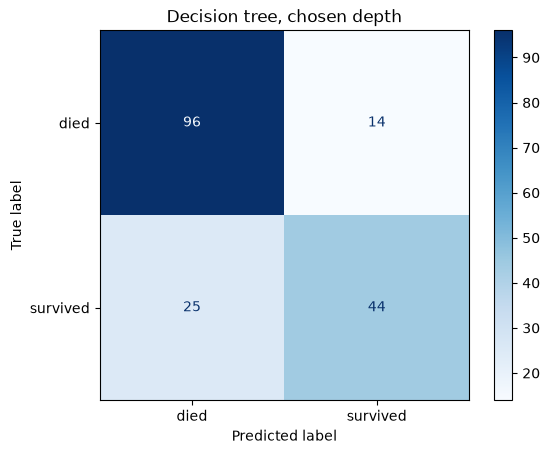

In [12]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import GridSearchCV, StratifiedKFold


def title_of(name):
    title = name.split(",")[1].split(".")[0].strip()
    if title in {"Mlle", "Ms"}:
        return "Miss"
    if title == "Mme":
        return "Mrs"
    if title in {"Mr", "Mrs", "Miss", "Master"}:
        return title
    return "Rare"


class TicketFeatures(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        frame = pd.DataFrame(X)
        titles = frame["Name"].map(title_of)
        self.age_by_title_ = frame.groupby(titles)["Age"].median()
        self.default_age_ = float(frame["Age"].median())
        return self

    def transform(self, X):
        frame = pd.DataFrame(X).copy()
        titles = frame["Name"].map(title_of)
        missing = frame["Age"].isna()
        filled = titles.map(self.age_by_title_).fillna(self.default_age_)
        frame.loc[missing, "Age"] = filled.loc[missing].to_numpy()
        family_size = frame["SibSp"] + frame["Parch"] + 1
        frame["Fare"] = frame["Fare"] / family_size
        return frame.drop(columns=["Name"])


detail_columns = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "Name"]
X_train_detail = df.loc[X_train.index, detail_columns]
X_test_detail = df.loc[X_test.index, detail_columns]

depth_tree = Pipeline(
    [
        ("ticket", TicketFeatures()),
        ("preprocess", make_preprocess(False)),
        ("classifier", DecisionTreeClassifier(random_state=42)),
    ]
)
depth_search = GridSearchCV(
    depth_tree,
    {"classifier__max_depth": [2, 3, 4, 5, 6, 8, 10, None]},
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring="accuracy",
    n_jobs=1,
    refit=True,
)
depth_search.fit(X_train_detail, y_train)
print("Age medians by title")
print(depth_search.best_estimator_.named_steps["ticket"].age_by_title_.round(1))
print("Chosen max_depth:", depth_search.best_params_["classifier__max_depth"])
print(f"Cross-validated accuracy: {depth_search.best_score_:.3f}")

open_tree = Pipeline(
    [
        ("ticket", TicketFeatures()),
        ("preprocess", make_preprocess(False)),
        ("classifier", DecisionTreeClassifier(random_state=42)),
    ]
)
open_tree.fit(X_train_detail, y_train)

tuned_pred = np.asarray(depth_search.predict(X_test_detail))
open_pred = np.asarray(open_tree.predict(X_test_detail))
header = f"{'tree':<24} {'accuracy':>10} {'survived recall':>16}"
print()
print(header)
print("-" * len(header))
for name, pred in (
    ("Unlimited depth", open_pred),
    ("Chosen depth", tuned_pred),
):
    print(
        f"{name:<24} {accuracy_score(y_test, pred):>10.3f} "
        f"{survived_recall(y_test, pred):>16.3f}"
    )

print()
print("Chosen depth")
print(classification_report(
    y_test,
    tuned_pred,
    target_names=outcome_names,
    zero_division=0,
))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    tuned_pred,
    display_labels=outcome_names,
    cmap="Blues",
)
plt.title("Decision tree, chosen depth")
plt.show()


## Age as bands

The training table already cuts age at 12, 18, 40, 60, and 80. Children survive more often than a straight line in age can show. This section fits the same logistic regression with those bands in the place of `Age`. A passenger with no recorded age has a band called `missing`. Family counts, fare, class, sex, and port stay as in the baseline.

Accuracy: 0.810
Always predict 0: 0.615

              precision    recall  f1-score   support

        died       0.81      0.90      0.85       110
    survived       0.81      0.67      0.73        69

    accuracy                           0.81       179
   macro avg       0.81      0.78      0.79       179
weighted avg       0.81      0.81      0.81       179



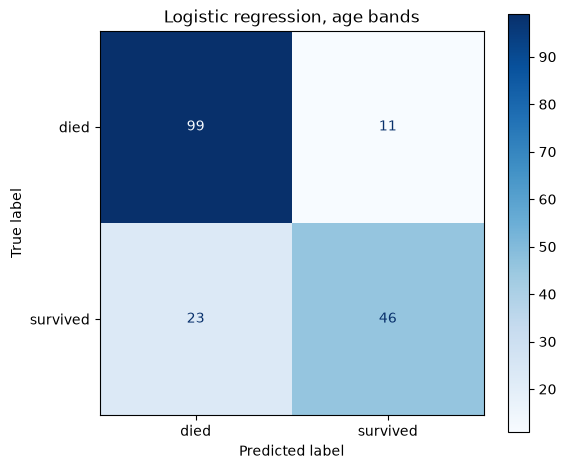

In [13]:
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X_train_bands = X_train.copy()
X_test_bands = X_test.copy()
age_edges = [0, 12, 18, 40, 60, 80]
X_train_bands["age_band"] = pd.cut(
    X_train_bands["Age"], age_edges, right=False
).astype(str)
X_test_bands["age_band"] = pd.cut(
    X_test_bands["Age"], age_edges, right=False
).astype(str)
X_train_bands.loc[X_train["Age"].isna(), "age_band"] = "missing"
X_test_bands.loc[X_test["Age"].isna(), "age_band"] = "missing"

band_numeric = ["SibSp", "Parch", "Fare"]
band_categorical = ["Pclass", "Sex", "Embarked", "age_band"]

band_preprocess = ColumnTransformer(
    [
        (
            "numeric",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                ]
            ),
            band_numeric,
        ),
        (
            "categorical",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    (
                        "onehot",
                        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                    ),
                ]
            ),
            band_categorical,
        ),
    ]
)
banded_model = Pipeline(
    [
        ("preprocess", band_preprocess),
        ("classifier", LogisticRegression(max_iter=10000)),
    ]
)
banded_model.fit(X_train_bands, y_train)
banded_pred = banded_model.predict(X_test_bands)
held_out = y_test.to_numpy()
predicted = np.asarray(banded_pred)
common_outcome = int(y_train.mode().iloc[0])
majority = np.full(len(held_out), common_outcome)
outcome_names = ["died", "survived"]

print(f"Accuracy: {accuracy_score(held_out, predicted):.3f}")
print(f"Always predict {common_outcome}: {accuracy_score(held_out, majority):.3f}")
print()
print(
    classification_report(
        held_out,
        predicted,
        target_names=outcome_names,
        zero_division=0,
    )
)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    held_out,
    predicted,
    display_labels=outcome_names,
    ax=ax,
    cmap="Blues",
)
ax.set_title("Logistic regression, age bands")
fig.tight_layout()
plt.show()


## Held-out passengers with age bands

On the 179 held-out passengers, accuracy is 0.810. The logistic regression with a straight age scores 0.804. Survived recall stays 0.667, so 23 of the 69 survivors are called dead. The one extra correct passenger is a death: death recall moves from 0.89 to 0.90.

The decision tree that leaves out `Sex_male` and keeps the ticket total stays the highest accuracy, at 0.827.

## Conclusion

`train.csv` has 891 passengers and a `Survived` label. `test.csv` has 418 passengers and no label, so every score below uses the same 179 held-out training passengers. Death is the common outcome: 549 died and 342 survived. Always predicting death scores 0.615.

Logistic regression, with missing ages filled by the training median, reaches accuracy 0.804. Survived recall is 0.667, so 23 of the 69 survivors are called dead.

`Name`, `Ticket`, and `Cabin` stay out. Sex becomes two columns, and port and class become one column each. Female sex, first and third class, and fare are the strong straight-line links. Age and `SibSp` look weak as a line and stay, because children and small families survive more often than that line suggests.

A decision tree, a random forest, and gradient boosting are fit on those columns. The tree reaches accuracy 0.816 and survived recall 0.725. The forest and boosting stay at 0.804.

`Sex_male` repeats `Sex_female`, so it is left out. Logistic regression stays at 0.804. The tree rises to 0.827, with survived precision 0.81 and recall 0.72. The forest rises to 0.810. Gradient boosting stays at 0.804, with survived recall 0.725.

A last tree replaces the ticket total with the fare per person and fills missing ages from the title: `Master` 3, `Miss` 22, `Mr` 30, `Mrs` 35, and rare titles 49. Depth 6 is chosen on the training passengers, with cross-validated accuracy 0.819. On the held-out passengers it scores 0.782, and survived recall 0.638. Unlimited depth with those features also scores 0.782.

The best of these is the decision tree that leaves out `Sex_male` and keeps the ticket total. On the 179 held-out passengers its accuracy is 0.827, with survived precision 0.81 and recall 0.72.

The same logistic regression is fit again with age bands at 12, 18, 40, 60, and 80 in the place of `Age`. Held-out accuracy is 0.810. Survived recall stays 0.667. The decision tree that leaves out `Sex_male` and keeps the ticket total stays the highest accuracy, at 0.827.
